In [6]:
import math
import matplotlib.pyplot as plt
import numpy as np

#Creating the intergrand function

def intgr1(x):
    y= ( ( x ** 4 * (1 - x)**4 ) / (1 + x**2) )
    return y

#Intergral function with lower and upper limits

def trap0 (f , a , b , n ):
    h = float (b - a )/ n
    s =0.5*( f(a) + f ( b ))
    for i in range (1 , n ):
        s = s + f ( a + i * h )
    return s * h

#Finding value for the intergral

print (f"Intergral with 100 trapeziums: {trap0(intgr1,0,1,100)}")
print (f"Intergral with 18 trapeziums:  {trap0(intgr1,0,1,18)}")
print("18 trapeziums in the minimum number to have an error of 6 significant figures")


Intergral with 100 trapeziums: 0.0012644892673714441
Intergral with 18 trapeziums:  0.0012644899090426126
18 trapeziums in the minimum number to have an error of 6 significant figures


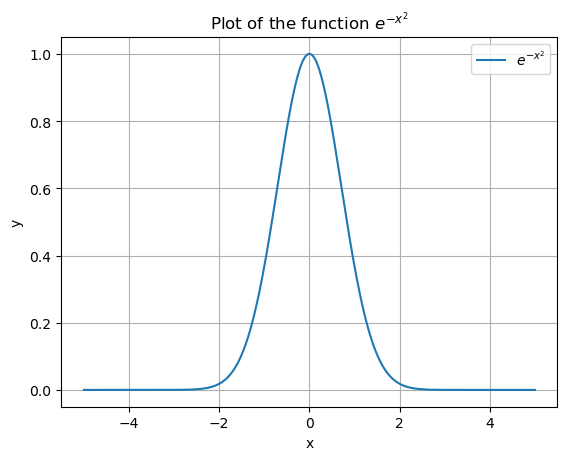

Plotting the function shows values approach zero outside of x = -4 and 4
This means we can use these as limits and get an accurate value for the intergral
Using limts of -4 to 4 intergral of exp(-x^2) = 1.7724538147284998
Using limts of -10 to 10 intergral of exp(-x^2) = 1.7724538509055157
This shows the values are similar after 4 becuase the graph goes to zero


In [7]:
#Specified Accuracy

def trap1(f, a, b, delta, maxtraps=512):  # Maxtraps is the max number of trapeziums
    n = 8
    inew = trap0(f, a, b, n)
    iold = -inew
    while math.fabs(inew - iold) > delta * math.fabs(inew):
        iold = inew
        n = 2 * n
        if n > maxtraps:
            print("Cannot reach requested accuracy with", maxtraps, "trapezia")
            return None
        inew = trap0(f, a, b, n)
    return inew

def intgr2(x):
    y = math.exp(-x**2)
    return y

# Plot the function

x_values = np.linspace(-5, 5, 400)
y_values = [intgr2(x) for x in x_values]


plt.plot(x_values, y_values, label=r"$e^{-x^2}$")
plt.title("Plot of the function $e^{-x^2}$")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.savefig("exponential_fig.png")
plt.show()

print("Plotting the function shows values approach zero outside of x = -4 and 4")
print("This means we can use these as limits and get an accurate value for the intergral")

## Testing intergral at differant ranges

print(f"Using limts of -4 to 4 intergral of exp(-x^2) = {trap1(intgr2,-4,4,1e-6)}")
print(f"Using limts of -10 to 10 intergral of exp(-x^2) = {trap1(intgr2,-10,10,1e-6)}")
print("This shows the values are similar after 4 becuase the graph goes to zero")



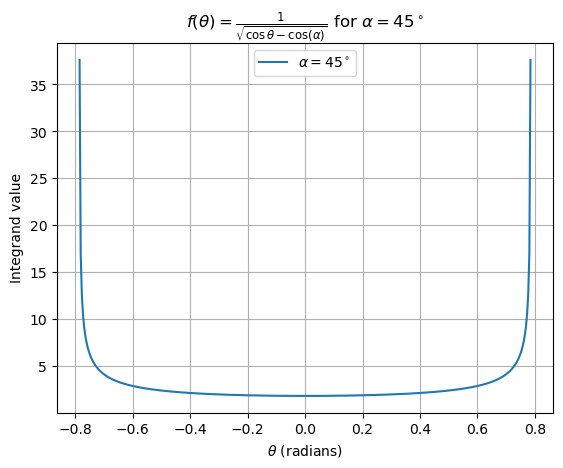

Graph shows intergrand is invalid beofre -alpha and after alpha


In [8]:
##3.5 pendulum equation

## plotting pendulum function 

alpha = np.pi / 4

def intgr3(theta, alpha):
    return 1 / np.sqrt(np.cos(theta) - np.cos(alpha))

## only valid between not valid past alpha and -alpha so change the range
theta = np.linspace(-alpha + 0.001 , alpha - 0.001 , 400) 

# Evaluate the function
y_values = intgr3(theta, alpha)

# Plot of new equation

plt.plot(theta, y_values, label=rf'$\alpha = 45^\circ$')
plt.xlabel(r"$\theta$ (radians)")
plt.ylabel("Integrand value")
plt.title(r"$f(\theta) = \frac{1}{\sqrt{\cos\theta - \cos(\alpha)}}$ for $\alpha = 45^\circ$")
plt.grid(True)
plt.legend()
plt.savefig("pendulum_fig.png")
plt.show()

print("Graph shows intergrand is invalid beofre -alpha and after alpha")

In [9]:
## new intergrand that doesnt go to inf

def intgr4(phi):
    y = 1 / np.sqrt(1 - (np.sin(alpha / 2))**2 * np.sin(phi)**2)
    return y


alpha_values = [0,15,30,45,60,75,90] # set of alphas that we want to test

# calculating the t/t0 values at the alphas

for i in alpha_values:        ##Loop through alpha values and evaluate the intergral for each alpha
    alpha = math.radians(i)
    integral = trap1(intgr4, 0, np.pi/2, 1e-6)
    ratio = (2/np.pi) * integral        ## times my 2/pi ti get the tn ratio
    
    print(f"T/T0 for alpha = {i}° is: {ratio:.6f}")  ## print out vaues


##value at 90 degrees with better accuracy

alpha = math.radians(90)
integral_90 = trap1(intgr4, 0, np.pi/2, 1e-12)  ## delta as 1e-12 for better uncertainty
ratio_90 = (2 / np.pi) * integral_90
print(f"Accurate T/T0 for 90° amplitude: {ratio_90:}")


T/T0 for alpha = 0° is: 1.000000
T/T0 for alpha = 15° is: 1.004301
T/T0 for alpha = 30° is: 1.017409
T/T0 for alpha = 45° is: 1.039973
T/T0 for alpha = 60° is: 1.073182
T/T0 for alpha = 75° is: 1.118959
T/T0 for alpha = 90° is: 1.180341
Accurate T/T0 for 90° amplitude: 1.1803405990160964


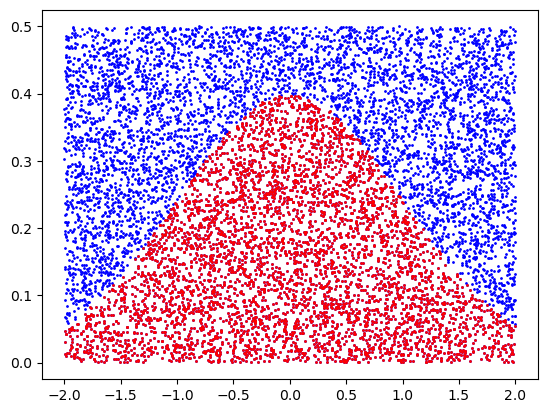

Probability within +- 2 std: 0.9608


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


# random point generators
random_x = np.random.uniform(-2, 2, 10000) #between +-2 because of 2 std
random_y = np.random.uniform(0, 0.5, 10000)

# gaussian function mean - 0 std - 1
Gauss_func = norm.pdf(random_x,0,1)

# points under the curve
points_under = random_y < Gauss_func

# plotting all the points shwoing poins under in red and above in blue
plt.scatter(random_x, random_y, s=1, color="blue")
plt.scatter(random_x[points_under], random_y[points_under], s=1, color="red")
plt.savefig("monte_carlo_fig.png")
plt.show()

area_rectangle =  4 * 0.5  # range in x and range in y

#fraction of  number of points under the curve over the total number of points
fraction_under_curve = np.sum(points_under) / len(random_x)  ##np.sum will give numbe of trues in the array

area_under = area_rectangle * fraction_under_curve

print(f"Probability within +- 2 std: {area_under}")




